# Comparación de KNN, árboles de clasificación y regresión logística para la predicción de malignidad en cáncer de mama

**Curso:** Inteligencia Artificial (1INF24) — Tarea Académica Grupal, Grupo 9
**Autores:** Franklin Aristides Muñoz Palomino, Adrian Andre Unda Vivanco, Matías Maldonado Marroquín y Jarel Josue Ramirez Altamirano

Este notebook implementa la metodología descrita en el **capítulo 3** del informe grupal. Se comparan tres algoritmos de clasificación supervisada —**K-Vecinos más cercanos (KNN)**, **árbol de clasificación** y **regresión logística**— sobre el dataset *Wisconsin Diagnostic Breast Cancer* (WDBC), priorizando el **recall de la clase maligna** para minimizar los falsos negativos.

**Pregunta de investigación:** ¿cuál de los algoritmos obtiene el mayor recall en la clase maligna, y con qué equilibrio respecto a la precisión?

**Hipótesis**
- **H1 (principal):** la regresión logística alcanzará un recall superior al 95 %, significativamente mayor que el del árbol de clasificación y al menos comparable al de KNN.
- **H2 (secundaria):** reducir los atributos a los tres de Street et al. (F3) conservará una accuracy cercana al 97 %, pero sin superar el recall obtenido con los 30 atributos (F30).

**Estructura del notebook**
1. Configuración del entorno
2. Carga de datos y formulación del problema (sección 3.1)
3. Análisis exploratorio que justifica las adaptaciones (sección 3.3, operadores 1 y 2)
4. Variantes de representación de atributos: F30, F3 y PCA95
5. Modelos y espacios de hiperparámetros (operadores 3, 4 y 5)
6. Protocolo de validación cruzada anidada (operador 6)
7. Resultados
8. Pruebas estadísticas (Nadeau-Bengio + Holm)
9. Verificación de hipótesis
10. Modelo final e interpretación
11. Discusión de resultados

## 1. Configuración del entorno

Se importan las librerías necesarias y se fija una **semilla aleatoria** global para que todos los experimentos sean reproducibles: con la misma semilla, las particiones de validación cruzada y los resultados serán idénticos en cada ejecución.

In [3]:
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, fbeta_score,
                             make_scorer, precision_score, recall_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
np.random.seed(SEED)

## 2. Carga de datos y formulación del problema

Siguiendo la **sección 3.1** del informe, el conjunto de datos es $D = \{(x_i, y_i)\}_{i=1}^{N}$ con $N = 569$ muestras. Cada $x_i \in \mathbb{R}^{30}$ contiene 30 mediciones morfométricas de los núcleos celulares (10 propiedades citológicas × 3 estadísticos: media, error estándar y peor valor).

La etiqueta se codifica como $y_i = 1$ si el tumor es **maligno** y $y_i = 0$ si es **benigno**, de modo que la condición clínica crítica sea la **clase positiva**. Así, el *recall* mide directamente la proporción de tumores malignos detectados:

$$\text{Recall} = \frac{TP}{TP + FN}$$

> **Nota sobre la recodificación:** el informe menciona que `sklearn.datasets.load_breast_cancer` codifica 0 = maligno y 1 = benigno, por lo que se aplica $y_i = 1 - \text{target}_i$. Aquí se lee el CSV original, cuya columna `diagnosis` contiene `M`/`B`; la asignación `M → 1`, `B → 0` es equivalente a esa recodificación.

En la lectura se eliminan dos columnas que no son atributos: `id` (identificador del paciente) y `Unnamed: 32` (columna vacía generada por una coma final en el CSV).

In [4]:
DATA_PATH = "data.csv"   # ajustar la ruta si el archivo tiene otro nombre

df = pd.read_csv(DATA_PATH)
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Clase positiva = maligno (1), clase negativa = benigno (0)
y = (df["diagnosis"] == "M").astype(int).to_numpy()
X = df.drop(columns="diagnosis")
FEATURES = X.columns.tolist()

print(f"Dimensión de X: {X.shape}  (muestras × atributos)")
print(f"Valores faltantes: {X.isna().sum().sum()}")
print(f"Malignos (y=1): {y.sum()}  |  Benignos (y=0): {(y == 0).sum()}")
X.head()

Dimensión de X: (569, 30)  (muestras × atributos)
Valores faltantes: 0
Malignos (y=1): 212  |  Benignos (y=0): 357


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.589,153.40,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.398,74.08,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.585,94.03,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.445,27.23,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.438,94.44,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


## 3. Análisis exploratorio

Esta sección reproduce las evidencias del análisis exploratorio que, según la **sección 3.3** del informe, motivan cada adaptación del pipeline: el desbalance de clases (→ `class_weight="balanced"`), la multicolinealidad (→ variantes F3 y PCA95, regularización L1/L2), los valores atípicos (→ se conservan) y las escalas heterogéneas (→ estandarización Z-score).

### 3.1 Distribución de clases

El dataset está moderadamente desbalanceado (≈ 63 % benignos y 37 % malignos). Por eso se usa **validación estratificada** (cada partición conserva la proporción de clases) y, en el árbol y la regresión logística, **ponderación de clases inversamente proporcional a su frecuencia**.

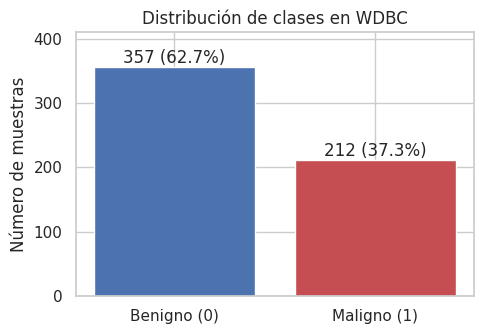

In [5]:
counts = pd.Series(y).map({0: "Benigno (0)", 1: "Maligno (1)"}).value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index, counts.values, color=["#4C72B0", "#C44E52"])
ax.bar_label(bars, labels=[f"{v} ({v / len(y):.1%})" for v in counts.values])
ax.set_ylabel("Número de muestras")
ax.set_title("Distribución de clases en WDBC")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

### 3.2 Multicolinealidad entre atributos

Varios atributos están casi perfectamente correlacionados porque describen la misma geometría del núcleo (radio, perímetro y área). La alta correlación:
- **distorsiona la distancia de KNN**, ya que la misma información “cuenta varias veces”;
- **desestabiliza los pesos de la regresión logística**, lo que justifica la regularización L1/L2;
- motiva las representaciones **F3** (pocos atributos) y **PCA95** (componentes ortogonales).

La celda siguiente cuenta los pares con $|r| > 0.90$ y muestra el mapa de calor de correlaciones.

Pares de atributos con |r| > 0.90: 21


,atributo_1,atributo_2,r
0,radius_mean,perimeter_mean,0.9979
1,radius_worst,perimeter_worst,0.9937
2,radius_mean,area_mean,0.9874
3,perimeter_mean,area_mean,0.9865
4,radius_worst,area_worst,0.9840
5,perimeter_worst,area_worst,0.9776
6,radius_se,perimeter_se,0.9728
7,perimeter_mean,perimeter_worst,0.9704
8,radius_mean,radius_worst,0.9695
9,perimeter_mean,radius_worst,0.9695


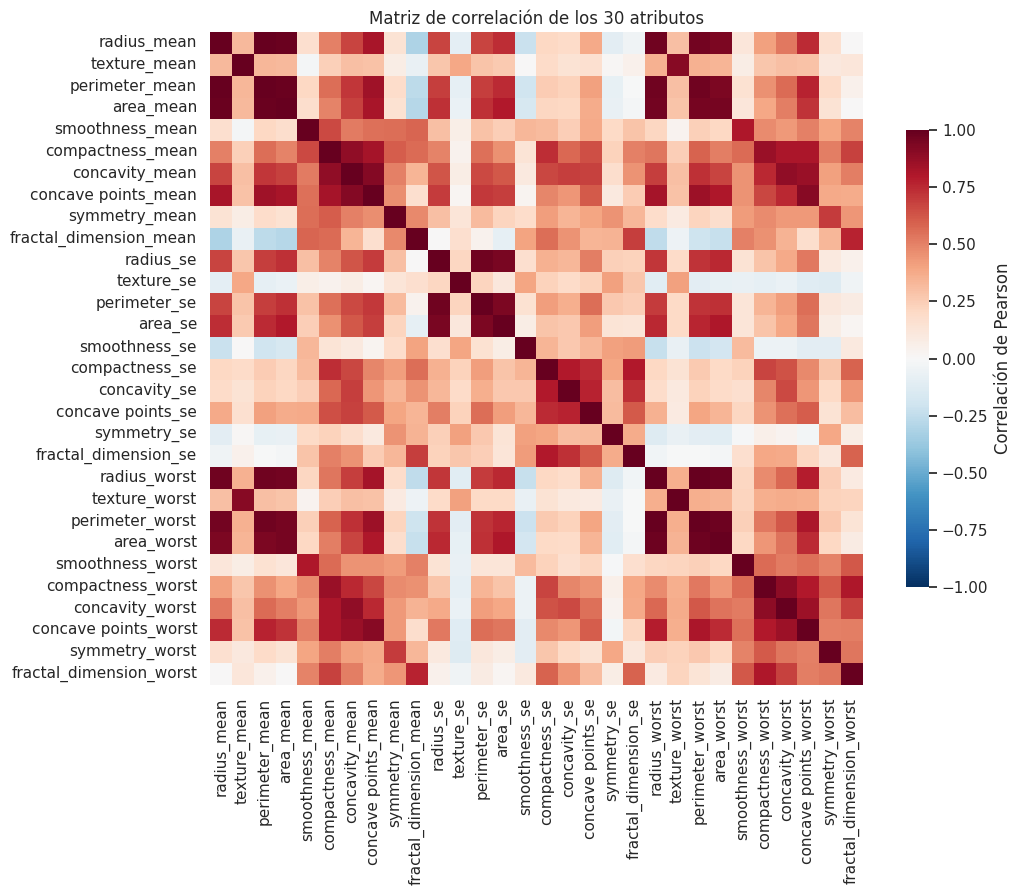

In [6]:
corr = X.corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_pairs = (upper.stack()
                   .rename("r")
                   .reset_index()
                   .rename(columns={"level_0": "atributo_1", "level_1": "atributo_2"}))
high_pairs = high_pairs[high_pairs["r"].abs() > 0.90].sort_values("r", key=np.abs, ascending=False)

print(f"Pares de atributos con |r| > 0.90: {len(high_pairs)}")
display(high_pairs.head(10).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.7, "label": "Correlación de Pearson"}, ax=ax)
ax.set_title("Matriz de correlación de los 30 atributos")
plt.tight_layout()
plt.show()

### 3.3 Valores atípicos (criterio IQR)

Un valor se considera atípico si cae fuera de $[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$. Se calcula, para cada clase, el porcentaje de muestras con **al menos un** atributo atípico.

Si los atípicos se concentran en la clase maligna, son **información clínica** (morfología de tumores agresivos) y no ruido. Por eso el pipeline **los conserva**.

Muestras malignas con al menos un valor atípico: 53.8%
Muestras benignas con al menos un valor atípico: 16.0%

Atípicos en 'area_worst': 35 (malignos: 35, benignos: 0)


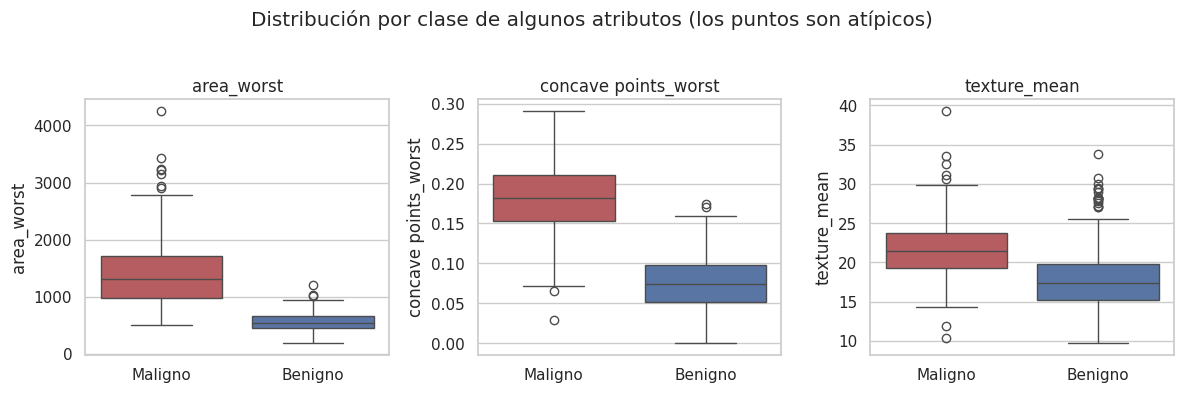

In [7]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
is_outlier = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)
has_outlier = is_outlier.any(axis=1)

for label, name in [(1, "malignas"), (0, "benignas")]:
    pct = has_outlier[y == label].mean()
    print(f"Muestras {name} con al menos un valor atípico: {pct:.1%}")

out_area = is_outlier["area_worst"]
print(f"\nAtípicos en 'area_worst': {out_area.sum()} "
      f"(malignos: {out_area[y == 1].sum()}, benignos: {out_area[y == 0].sum()})")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
plot_df = X.assign(diagnóstico=np.where(y == 1, "Maligno", "Benigno"))
for ax, col in zip(axes, ["area_worst", "concave points_worst", "texture_mean"]):
    sns.boxplot(data=plot_df, x="diagnóstico", y=col, ax=ax,
                palette={"Benigno": "#4C72B0", "Maligno": "#C44E52"})
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distribución por clase de algunos atributos (los puntos son atípicos)", y=1.03)
plt.tight_layout()
plt.show()

### 3.4 Escalas heterogéneas

Los atributos difieren en varios órdenes de magnitud (por ejemplo, el área supera 4000 mientras la dimensión fractal es del orden de $10^{-2}$). Los métodos basados en distancias (KNN), en descenso por gradiente con penalización (regresión logística) y en varianza (PCA) son sensibles a la escala, por lo que se aplica la **estandarización Z-score** $z = (x - \mu)/\sigma$.

El árbol de clasificación **no** requiere estandarizar: sus cortes son umbrales sobre un solo atributo y son invariantes a transformaciones monótonas.

In [8]:
escala = X.describe().T[["mean", "std", "min", "max"]]
display(escala.loc[["area_worst", "area_mean", "radius_mean",
                    "smoothness_mean", "fractal_dimension_mean", "fractal_dimension_se"]])

,mean,std,min,max
area_worst,880.5831,569.3570,185.2000,4254.0000
area_mean,654.8891,351.9141,143.5000,2501.0000
radius_mean,14.1273,3.5240,6.9810,28.1100
smoothness_mean,0.0964,0.0141,0.0526,0.1634
fractal_dimension_mean,0.0628,0.0071,0.0500,0.0974
fractal_dimension_se,0.0038,0.0026,0.0009,0.0298


## 4. Variantes de representación de atributos

Cada algoritmo se evalúa sobre los **tres espacios de entrada** definidos en el informe (operador 2):

| Variante | Dimensión | Descripción |
|---|---|---|
| **F30** | 30 | Los 30 atributos originales |
| **F3** | 3 | `texture_mean`, `area_worst` y `smoothness_worst`, seleccionados por Street et al. [2] |
| **PCA95** | variable | Componentes principales que retienen el 95 % de la varianza (sobre datos estandarizados) |

**Prevención de fuga de información (*data leakage*):** la estandarización y el PCA se implementan como pasos de un `Pipeline` de scikit-learn. Así, $\mu$, $\sigma$ y los componentes principales se calculan **solo con la partición de entrenamiento de cada fold** y luego se aplican a la partición de prueba.

La función `build_pipeline` construye el pipeline adecuado para cada combinación (representación, modelo):
- **F30:** [estandarización] → modelo
- **F3:** selección de 3 columnas → [estandarización] → modelo
- **PCA95:** estandarización → PCA(95 %) → modelo

La estandarización entre corchetes se omite para el árbol.

In [9]:
F3_FEATURES = ["texture_mean", "area_worst", "smoothness_worst"]
REPRESENTATIONS = ["F30", "F3", "PCA95"]


def build_pipeline(representation, estimator, scale=True):
    # Construye el pipeline de preprocesamiento + clasificador.
    steps = []
    if representation == "F3":
        steps.append(("select", ColumnTransformer([("f3", "passthrough", F3_FEATURES)],
                                                  remainder="drop")))
    if representation == "PCA95":
        steps.append(("scaler", StandardScaler()))
        steps.append(("pca", PCA(n_components=0.95, svd_solver="full", random_state=SEED)))
    elif scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", estimator))
    return Pipeline(steps)

**Exploración ilustrativa del PCA.** Para dar una idea del tamaño de PCA95, se ajusta el PCA sobre el dataset completo. *Esto es solo descriptivo:* dentro de la validación cruzada el PCA se reajusta en cada fold de entrenamiento, por lo que el número de componentes puede variar ligeramente entre folds.

Componentes necesarios para retener el 95 % de la varianza: 10


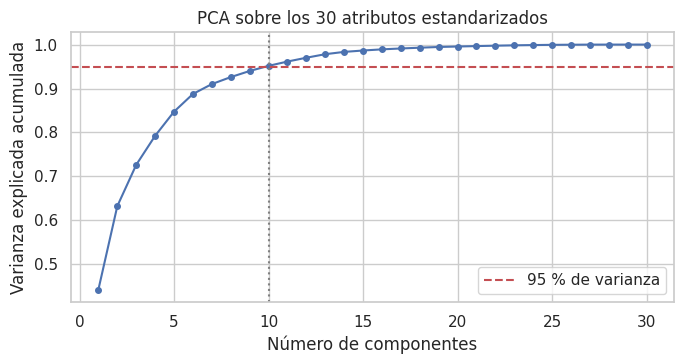

In [10]:
pca_full = PCA(svd_solver="full").fit(StandardScaler().fit_transform(X))
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum_var >= 0.95) + 1)
print(f"Componentes necesarios para retener el 95 % de la varianza: {n95}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(range(1, 31), cum_var, marker="o", ms=4)
ax.axhline(0.95, color="#C44E52", ls="--", label="95 % de varianza")
ax.axvline(n95, color="gray", ls=":")
ax.set_xlabel("Número de componentes")
ax.set_ylabel("Varianza explicada acumulada")
ax.set_title("PCA sobre los 30 atributos estandarizados")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Modelos y espacios de hiperparámetros

Se definen los tres clasificadores y sus grillas de búsqueda tal como se describen en los operadores 3, 4 y 5 del informe.

**KNN (operador 3).** Distancia de Minkowski $d_p(z_q, z_i) = \left(\sum_j |z_{qj} - z_{ij}|^p\right)^{1/p}$ con $p \in \{1, 2\}$ (Manhattan y Euclidiana); $k$ impar en $\{1, 3, \dots, 21\}$ para evitar empates; voto uniforme o ponderado por $w_i = 1/d_p$.

**Árbol de clasificación (operador 4).** Impureza de Gini $I_G = 1 - \sum_c p_c^2$ o entropía $I_H = -\sum_c p_c \log_2 p_c$; poda preventiva con profundidad máxima $d_{max} \in \{2, 3, 4, 5, 8, \text{sin límite}\}$, mínimo de muestras por hoja $m_{min} \in \{1, 5\}$ y poda por costo-complejidad $\alpha \in \{0, 0.01\}$; `class_weight="balanced"`.

**Regresión logística (operador 5).** $P(y=1 \mid z) = \sigma(w^\top z + b)$ con regularización L1 (Lasso) o L2 (Ridge), $C \in \{0.01, 0.1, 1, 10, 100\}$ y `class_weight="balanced"`. Se usa el *solver* `liblinear`, que admite ambas penalizaciones.

**Métrica de ajuste interno: F2.** Un clasificador que siempre predice “maligno” tendría recall = 1 con especificidad nula. Para evitar soluciones degeneradas, los hiperparámetros se eligen maximizando

$$F_2 = \frac{5 \cdot \text{Precision} \cdot \text{Recall}}{4 \cdot \text{Precision} + \text{Recall}},$$

que da más peso al recall sin ignorar la precisión.

In [11]:
MODELS = {
    "KNN": {
        "estimator": KNeighborsClassifier(),
        "scale": True,
        "grid": {
            "clf__n_neighbors": list(range(1, 22, 2)),
            "clf__p": [1, 2],
            "clf__weights": ["uniform", "distance"],
        },
    },
    "Árbol": {
        "estimator": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        "scale": False,   # el árbol es invariante a la escala
        "grid": {
            "clf__criterion": ["gini", "entropy"],
            "clf__max_depth": [2, 3, 4, 5, 8, None],
            "clf__min_samples_leaf": [1, 5],
            "clf__ccp_alpha": [0.0, 0.01],
        },
    },
    "Reg. logística": {
        "estimator": LogisticRegression(solver="liblinear", class_weight="balanced",
                                        max_iter=5000, random_state=SEED),
        "scale": True,
        "grid": {
            "clf__penalty": ["l1", "l2"],
            "clf__C": [0.01, 0.1, 1, 10, 100],
        },
    },
}

f2_scorer = make_scorer(fbeta_score, beta=2)

resumen_grillas = pd.DataFrame({
    nombre: {"Hiperparámetros": ", ".join(k.replace("clf__", "") for k in cfg["grid"]),
             "Combinaciones": int(np.prod([len(v) for v in cfg["grid"].values()]))}
    for nombre, cfg in MODELS.items()
}).T
resumen_grillas

,Hiperparámetros,Combinaciones
KNN,"n_neighbors, p, weights",44
Árbol,"criterion, max_depth, min_samples_leaf, ccp_alpha",48
Reg. logística,"penalty, C",10


## 6. Protocolo de validación cruzada anidada

Implementa el operador 6 del informe y el flujo de la Figura 1:

- **Lazo externo** (estimación del desempeño): validación cruzada estratificada de **10 particiones con 3 repeticiones** → 30 evaluaciones por configuración.
- **Lazo interno** (selección de hiperparámetros): `GridSearchCV` con validación cruzada estratificada de **5 particiones**, optimizando **F2**, ejecutada solo sobre la parte de entrenamiento del fold externo.

Así, los datos de prueba de cada fold externo nunca participan ni en el preprocesamiento ni en la selección de hiperparámetros, lo que da una estimación no sesgada del error de generalización.

**Comparaciones pareadas.** Todas las configuraciones usan **exactamente las mismas 30 particiones externas** (se generan una sola vez). Esto es requisito de la prueba t pareada de la sección 8.

En cada fold externo se registran: recall (sensibilidad), especificidad, precisión, F2, accuracy y AUC-ROC, junto con los hiperparámetros elegidos y las probabilidades predichas.

In [12]:
N_SPLITS_OUTER, N_REPEATS, N_SPLITS_INNER = 10, 3, 5

outer_cv = RepeatedStratifiedKFold(n_splits=N_SPLITS_OUTER, n_repeats=N_REPEATS,
                                   random_state=SEED)
OUTER_SPLITS = list(outer_cv.split(X, y))   # se fijan una vez para todos los modelos
inner_cv = StratifiedKFold(n_splits=N_SPLITS_INNER, shuffle=True, random_state=SEED)


def compute_metrics(y_true, y_pred, y_score):
    # Métricas de evaluación con la clase maligna (1) como positiva.
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "especificidad": tn / (tn + fp),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "f2": fbeta_score(y_true, y_pred, beta=2, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_score),
        "tp": tp, "fn": fn, "fp": fp, "tn": tn,
    }


def nested_cv(pipeline, grid=None):
    # Ejecuta la validación cruzada anidada sobre OUTER_SPLITS.
    # Si grid es None, el pipeline se entrena sin búsqueda interna (clasificadores base).
    rows, oof = [], []
    for fold_id, (tr, te) in enumerate(OUTER_SPLITS):
        X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y[tr], y[te]
        if grid is None:
            model, best_params = clone(pipeline).fit(X_tr, y_tr), {}
        else:
            search = GridSearchCV(clone(pipeline), grid, scoring=f2_scorer,
                                  cv=inner_cv, n_jobs=-1, refit=True)
            search.fit(X_tr, y_tr)
            model, best_params = search.best_estimator_, search.best_params_
        y_score = model.predict_proba(X_te)[:, 1]      # p̂ = P(y=1 | x)
        y_pred = (y_score >= 0.5).astype(int)          # ŷ = 1 si p̂ ≥ 0.5
        row = {"fold": fold_id, "repeticion": fold_id // N_SPLITS_OUTER,
               **compute_metrics(y_te, y_pred, y_score),
               "best_params": {k.replace("clf__", ""): v for k, v in best_params.items()}}
        if "pca" in model.named_steps:
            row["n_componentes"] = model.named_steps["pca"].n_components_
        rows.append(row)
        oof.append(pd.DataFrame({"fold": fold_id, "repeticion": fold_id // N_SPLITS_OUTER,
                                 "idx": te, "y_true": y_te, "y_score": y_score}))
    return pd.DataFrame(rows), pd.concat(oof, ignore_index=True)

### 6.1 Clasificadores base (*Dummy*)

Para verificar que los modelos aprenden algo útil, se evalúan tres clasificadores base sobre las mismas particiones:
- **Mayoritario:** siempre predice “benigno” → recall = 0.
- **Estratificado:** predice al azar respetando la proporción de clases.
- **Siempre maligno:** recall = 1 pero especificidad = 0 (la solución degenerada que F2 busca evitar).

In [13]:
DUMMIES = {
    "Dummy mayoritario": DummyClassifier(strategy="most_frequent"),
    "Dummy estratificado": DummyClassifier(strategy="stratified", random_state=SEED),
    "Dummy siempre maligno": DummyClassifier(strategy="constant", constant=1),
}

dummy_results = []
for name, est in DUMMIES.items():
    res, _ = nested_cv(Pipeline([("clf", est)]))
    res.insert(0, "modelo", name)
    dummy_results.append(res)
dummy_results = pd.concat(dummy_results, ignore_index=True)

(dummy_results.groupby("modelo")[["recall", "especificidad", "precision", "f2", "accuracy", "auc"]]
              .mean().round(3))

,recall,especificidad,precision,f2,accuracy,auc
modelo,,,,,,
Dummy estratificado,0.292,0.669,0.344,0.301,0.529,0.481
Dummy mayoritario,0.000,1.000,0.000,0.000,0.627,0.500
Dummy siempre maligno,1.000,0.000,0.373,0.748,0.373,0.500


### 6.2 Experimento principal: 3 modelos × 3 representaciones

Se ejecuta la validación cruzada anidada para las 9 configuraciones. Cada configuración entrena $30 \times 5 \times |\text{grilla}|$ modelos en el lazo interno. En nuestra ejecución tardó unos **10 minutos** en un equipo con 2 núcleos (en Google Colab el tiempo es similar). La configuración más lenta es la regresión logística con F30, porque el *solver* `liblinear` converge lentamente con penalización L1 y valores altos de $C$. Al terminar, los resultados por fold se guardan en `resultados_cv_anidada.csv`.

In [14]:
all_results, all_oof = [], []
t0 = time.time()
for model_name, cfg in MODELS.items():
    for rep in REPRESENTATIONS:
        t = time.time()
        pipe = build_pipeline(rep, cfg["estimator"], scale=cfg["scale"])
        res, oof = nested_cv(pipe, cfg["grid"])
        res.insert(0, "representacion", rep)
        res.insert(0, "modelo", model_name)
        oof.insert(0, "representacion", rep)
        oof.insert(0, "modelo", model_name)
        all_results.append(res)
        all_oof.append(oof)
        print(f"{model_name:15s} | {rep:5s} | recall = {res['recall'].mean():.4f} "
              f"| F2 = {res['f2'].mean():.4f} | {time.time() - t:5.1f} s")
print(f"\nTiempo total: {(time.time() - t0) / 60:.1f} min")

results = pd.concat(all_results, ignore_index=True)
oof_preds = pd.concat(all_oof, ignore_index=True)
results.drop(columns="best_params").to_csv("resultados_cv_anidada.csv", index=False)

KNN             | F30   | recall = 0.9369 | F2 = 0.9418 |  76.9 s
KNN             | F3    | recall = 0.9117 | F2 = 0.9193 |  58.8 s
KNN             | PCA95 | recall = 0.9293 | F2 = 0.9335 |  72.0 s
Árbol           | F30   | recall = 0.9199 | F2 = 0.9124 |  91.9 s
Árbol           | F3    | recall = 0.9293 | F2 = 0.9230 |  59.7 s
Árbol           | PCA95 | recall = 0.9417 | F2 = 0.9327 |  89.5 s
Reg. logística  | F30   | recall = 0.9605 | F2 = 0.9601 | 726.9 s
Reg. logística  | F3    | recall = 0.9668 | F2 = 0.9661 |  14.5 s
Reg. logística  | PCA95 | recall = 0.9638 | F2 = 0.9627 |  19.9 s

Tiempo total: 20.2 min


## 7. Resultados

### 7.1 Tabla resumen

Media ± desviación estándar de cada métrica sobre las 30 evaluaciones externas. La métrica principal es el **recall** (sensibilidad en la clase maligna); F2, precisión, especificidad, accuracy y AUC permiten valorar el equilibrio con los falsos positivos. Las celdas resaltadas indican el mejor valor de cada columna.

In [15]:
METRICS = ["recall", "f2", "precision", "especificidad", "accuracy", "auc"]
MODEL_ORDER = list(MODELS)

summary_mean = results.groupby(["modelo", "representacion"], sort=False)[METRICS].mean()
summary_std = results.groupby(["modelo", "representacion"], sort=False)[METRICS].std()

tabla = summary_mean.copy().astype(object)
for m in METRICS:
    tabla[m] = [f"{mu:.4f} ± {sd:.4f}" for mu, sd in zip(summary_mean[m], summary_std[m])]

def resaltar_max(col):
    best = summary_mean[col.name].max()
    return ["font-weight: bold; background-color: #d4edda" if v == best else ""
            for v in summary_mean[col.name]]

display(tabla.style.apply(resaltar_max, axis=0))

### 7.2 Distribución del recall y F2 entre folds

Los diagramas de caja muestran la variabilidad de cada configuración en las 30 evaluaciones. Una caja estrecha y alta indica un modelo que detecta los malignos de forma consistente. La línea discontinua marca el umbral de 95 % de recall planteado en la hipótesis H1.

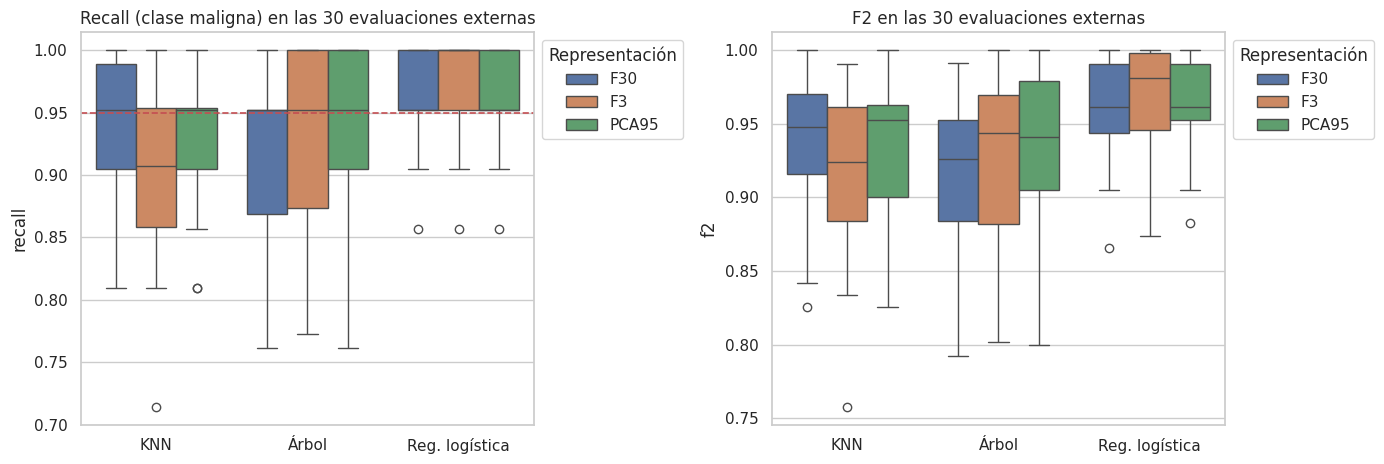

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=False)
palette = {"F30": "#4C72B0", "F3": "#DD8452", "PCA95": "#55A868"}
for ax, metric, title in zip(axes, ["recall", "f2"], ["Recall (clase maligna)", "F2"]):
    sns.boxplot(data=results, x="modelo", y=metric, hue="representacion",
                order=MODEL_ORDER, hue_order=REPRESENTATIONS, palette=palette, ax=ax)
    ax.set_title(f"{title} en las 30 evaluaciones externas")
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.legend(title="Representación", loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[0].axhline(0.95, color="#C44E52", ls="--", lw=1.2)
plt.tight_layout()
plt.show()

### 7.3 Matrices de confusión agregadas

Se suman las matrices de confusión de los 10 folds de cada repetición y se promedian las 3 repeticiones. El resultado equivale a la matriz de confusión “típica” de clasificar las 569 muestras una vez. La celda inferior izquierda corresponde a los **falsos negativos** (malignos clasificados como benignos), el error clínicamente más costoso.

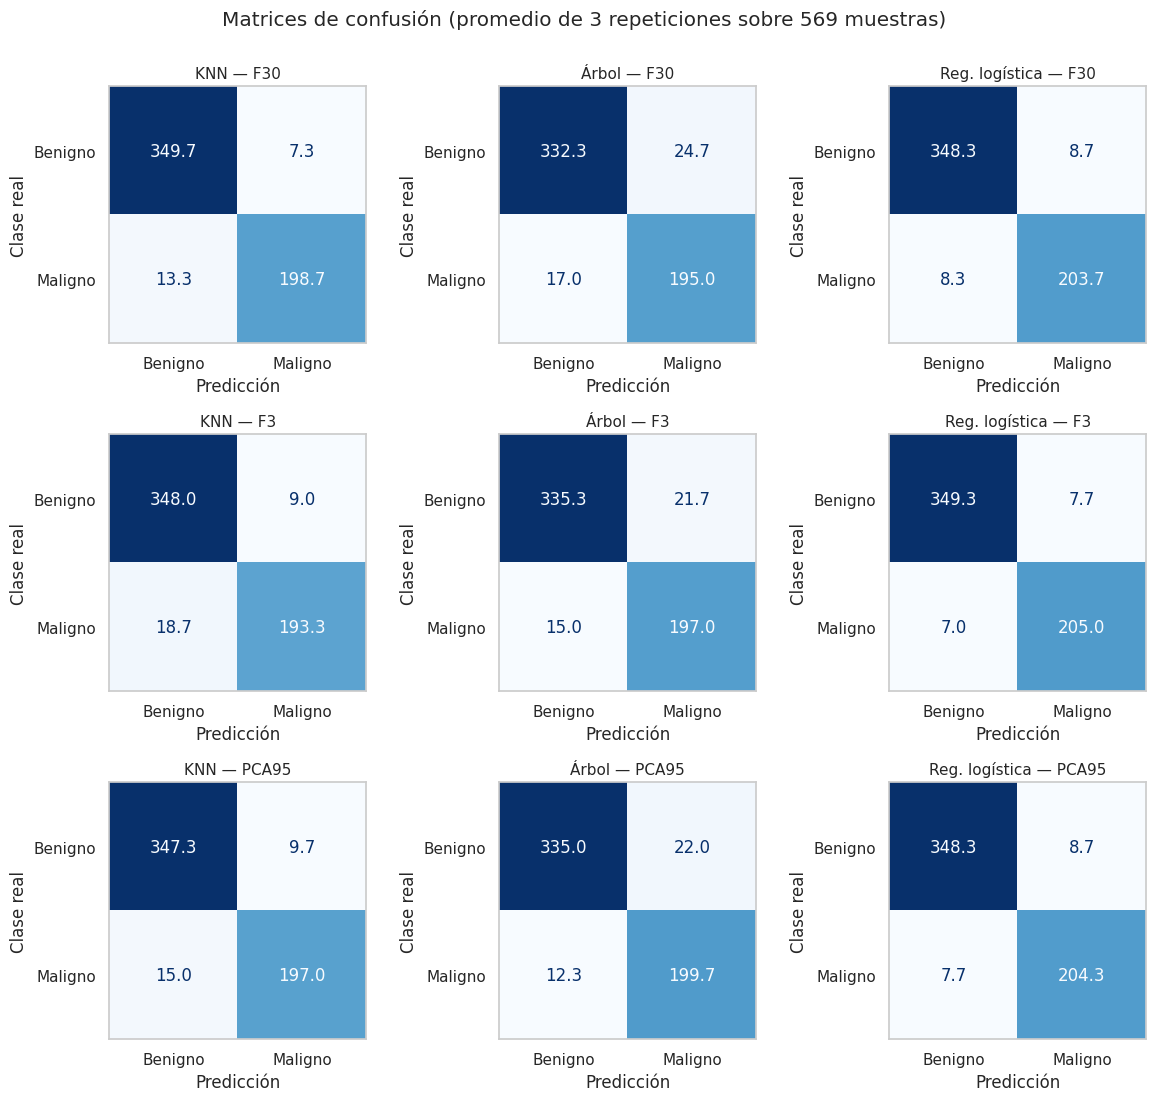

In [17]:
fig, axes = plt.subplots(len(REPRESENTATIONS), len(MODEL_ORDER), figsize=(12, 11))
for i, rep in enumerate(REPRESENTATIONS):
    for j, model_name in enumerate(MODEL_ORDER):
        sub = results[(results.modelo == model_name) & (results.representacion == rep)]
        cm = np.array([[sub.tn.sum(), sub.fp.sum()],
                       [sub.fn.sum(), sub.tp.sum()]]) / N_REPEATS
        ConfusionMatrixDisplay(cm, display_labels=["Benigno", "Maligno"]).plot(
            ax=axes[i, j], cmap="Blues", colorbar=False, values_format=".1f")
        axes[i, j].set_title(f"{model_name} — {rep}", fontsize=11)
        axes[i, j].set_xlabel("Predicción")
        axes[i, j].set_ylabel("Clase real")
        axes[i, j].grid(False)
plt.suptitle("Matrices de confusión (promedio de 3 repeticiones sobre 569 muestras)", y=1.0)
plt.tight_layout()
plt.show()

### 7.4 Curvas ROC

Las curvas ROC se construyen con las probabilidades *out-of-fold* de la primera repetición (cada muestra se predice exactamente una vez, por un modelo que no la vio en entrenamiento). Permiten ver el equilibrio entre sensibilidad y tasa de falsos positivos para todos los umbrales posibles, no solo para $\hat p \geq 0.5$.

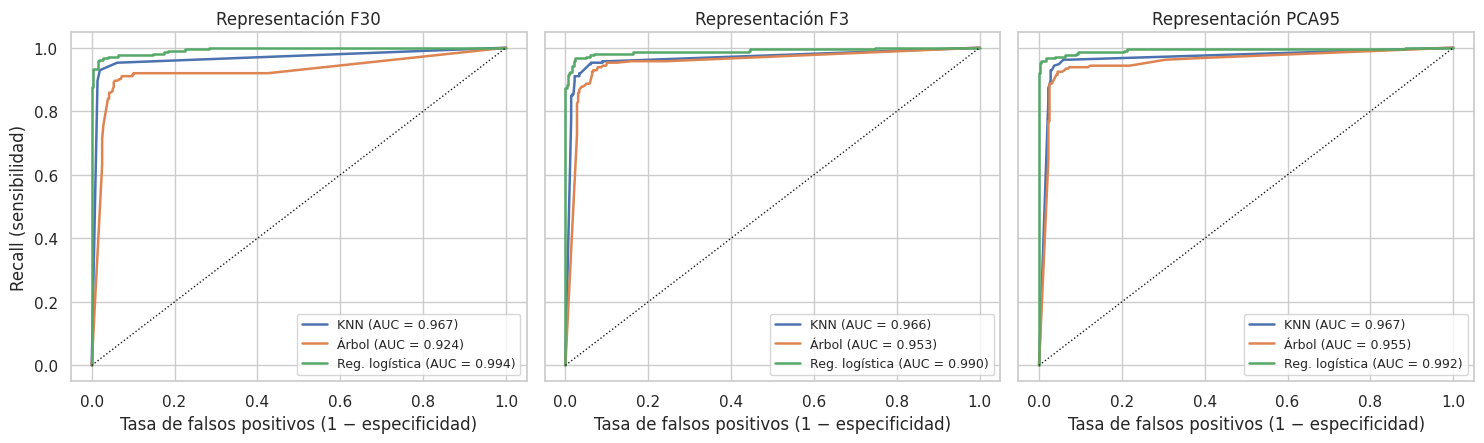

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, rep in zip(axes, REPRESENTATIONS):
    for model_name in MODEL_ORDER:
        sub = oof_preds[(oof_preds.modelo == model_name) &
                        (oof_preds.representacion == rep) & (oof_preds.repeticion == 0)]
        fpr, tpr, _ = roc_curve(sub.y_true, sub.y_score)
        ax.plot(fpr, tpr, lw=1.8,
                label=f"{model_name} (AUC = {roc_auc_score(sub.y_true, sub.y_score):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1)
    ax.set_title(f"Representación {rep}")
    ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)")
    ax.legend(loc="lower right", fontsize=9)
axes[0].set_ylabel("Recall (sensibilidad)")
plt.tight_layout()
plt.show()

### 7.5 Hiperparámetros seleccionados

En cada uno de los 30 folds externos el lazo interno puede elegir hiperparámetros distintos. La tabla muestra la combinación más frecuente y cuántas veces fue elegida; una frecuencia alta indica que la selección es **estable**. Para PCA95 también se reporta el número medio de componentes retenidos.

In [19]:
rows = []
for (model_name, rep), sub in results.groupby(["modelo", "representacion"], sort=False):
    combos = Counter(str(p) for p in sub.best_params)
    top, freq = combos.most_common(1)[0]
    row = {"modelo": model_name, "representacion": rep,
           "combinación más frecuente": top, "frecuencia": f"{freq}/30",
           "combinaciones distintas": len(combos)}
    if rep == "PCA95":
        row["componentes (media)"] = round(sub.n_componentes.mean(), 1)
    rows.append(row)
pd.DataFrame(rows).fillna("")

,modelo,representacion,combinación más frecuente,frecuencia,combinaciones distintas,componentes (media)
0,KNN,F30,"{'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}",18/30,6,
1,KNN,F3,"{'n_neighbors': 5, 'p': 1, 'weights': 'distance'}",9/30,9,
2,KNN,PCA95,"{'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}",11/30,10,10.0
3,Árbol,F30,"{'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...",4/30,18,
4,Árbol,F3,"{'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...",8/30,14,
5,Árbol,PCA95,"{'ccp_alpha': 0.01, 'criterion': 'gini', 'max_...",4/30,17,10.0
6,Reg. logística,F30,"{'C': 0.1, 'penalty': 'l2'}",14/30,5,
7,Reg. logística,F3,"{'C': 10, 'penalty': 'l1'}",19/30,4,
8,Reg. logística,PCA95,"{'C': 0.1, 'penalty': 'l2'}",17/30,5,10.0


## 8. Pruebas estadísticas

### 8.1 Prueba t pareada corregida de Nadeau y Bengio

Con validación cruzada repetida, los conjuntos de entrenamiento de distintos folds se solapan y las 30 diferencias no son independientes. La prueba t usual **subestima la varianza** y declara diferencias significativas con demasiada frecuencia. Nadeau y Bengio [5] proponen corregir la varianza:

$$t = \frac{\bar d}{\sqrt{\left(\frac{1}{J} + \frac{n_{test}}{n_{train}}\right)\hat\sigma_d^2}}, \qquad gl = J - 1$$

donde $d_j$ es la diferencia de la métrica entre dos modelos en el fold $j$, $J = 30$ es el número de evaluaciones y $n_{test}/n_{train} \approx 1/9$ en una validación de 10 particiones.

### 8.2 Ajuste de Holm

Como se realizan varias comparaciones simultáneas, se ajustan los p-valores con el método de Holm (*step-down*) para controlar la tasa de error por familia (FWER) en $\alpha = 0.05$: los p-valores se ordenan de menor a mayor, el $i$-ésimo se multiplica por $(m - i + 1)$ y se impone monotonía.

In [20]:
N_TEST = len(OUTER_SPLITS[0][1])
N_TRAIN = len(OUTER_SPLITS[0][0])
ALPHA = 0.05


def corrected_ttest(a, b, alternative="two-sided"):
    # Prueba t pareada con varianza corregida de Nadeau-Bengio.
    d = np.asarray(a) - np.asarray(b)
    J = len(d)
    var = d.var(ddof=1)
    if var == 0:   # diferencias idénticas en todos los folds
        return d.mean(), np.nan, (1.0 if d.mean() == 0 else 0.0)
    t = d.mean() / np.sqrt((1 / J + N_TEST / N_TRAIN) * var)
    if alternative == "two-sided":
        p = 2 * stats.t.sf(abs(t), df=J - 1)
    elif alternative == "greater":
        p = stats.t.sf(t, df=J - 1)
    else:
        p = stats.t.cdf(t, df=J - 1)
    return d.mean(), t, p


def holm(pvalues):
    # Ajuste de Holm-Bonferroni.
    p = np.asarray(pvalues, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[idx]))
        adj[idx] = running
    return adj


def get_scores(model_name, rep, metric="recall"):
    sub = results[(results.modelo == model_name) & (results.representacion == rep)]
    return sub.sort_values("fold")[metric].to_numpy()


def comparison_table(pairs, metric="recall", alternative="two-sided"):
    # pairs: lista de ((modelo_A, rep_A), (modelo_B, rep_B)).
    rows = []
    for (ma, ra), (mb, rb) in pairs:
        diff, t, p = corrected_ttest(get_scores(ma, ra, metric),
                                     get_scores(mb, rb, metric), alternative)
        rows.append({"A": f"{ma} ({ra})", "B": f"{mb} ({rb})",
                     f"media A": get_scores(ma, ra, metric).mean(),
                     f"media B": get_scores(mb, rb, metric).mean(),
                     "diferencia (A−B)": diff, "t": t, "p": p})
    out = pd.DataFrame(rows)
    out["p (Holm)"] = holm(out["p"])
    out["significativo"] = np.where(out["p (Holm)"] < ALPHA, "Sí", "No")
    return out

print(f"n_train = {N_TRAIN}, n_test = {N_TEST}, factor de corrección = "
      f"1/30 + {N_TEST}/{N_TRAIN} = {1/30 + N_TEST/N_TRAIN:.4f}")

n_train = 512, n_test = 57, factor de corrección = 1/30 + 57/512 = 0.1447


### 8.3 Comparación entre modelos (recall)

Para cada representación se comparan los tres pares de modelos. La familia de comparaciones para el ajuste de Holm es el conjunto completo de 9 pruebas (3 pares × 3 representaciones).

In [21]:
pairs_models = [((a, rep), (b, rep))
                for rep in REPRESENTATIONS
                for a, b in [("Reg. logística", "Árbol"),
                             ("Reg. logística", "KNN"),
                             ("KNN", "Árbol")]]
cmp_models = comparison_table(pairs_models, metric="recall")
cmp_models.round(4)

,A,B,media A,media B,diferencia (A−B),t,p,p (Holm),significativo
0,Reg. logística (F30),Árbol (F30),0.9605,0.9199,0.0406,1.3908,0.1749,0.8744,No
1,Reg. logística (F30),KNN (F30),0.9605,0.9369,0.0237,1.5269,0.1376,0.8257,No
2,KNN (F30),Árbol (F30),0.9369,0.9199,0.0170,0.6136,0.5443,1.0000,No
3,Reg. logística (F3),Árbol (F3),0.9668,0.9293,0.0375,1.9900,0.0561,0.3926,No
4,Reg. logística (F3),KNN (F3),0.9668,0.9117,0.0551,3.0924,0.0044,0.0392,Sí
5,KNN (F3),Árbol (F3),0.9117,0.9293,-0.0176,-0.8059,0.4269,1.0000,No
6,Reg. logística (PCA95),Árbol (PCA95),0.9638,0.9417,0.0221,1.1455,0.2614,1.0000,No
7,Reg. logística (PCA95),KNN (PCA95),0.9638,0.9293,0.0345,2.4475,0.0207,0.1654,No
8,KNN (PCA95),Árbol (PCA95),0.9293,0.9417,-0.0124,-0.6215,0.5391,1.0000,No


La misma comparación con **F2**, para comprobar si las diferencias en recall se mantienen al considerar también la precisión:

In [22]:
comparison_table(pairs_models, metric="f2").round(4)

,A,B,media A,media B,diferencia (A−B),t,p,p (Holm),significativo
0,Reg. logística (F30),Árbol (F30),0.9601,0.9124,0.0477,2.0128,0.0535,0.3210,No
1,Reg. logística (F30),KNN (F30),0.9601,0.9418,0.0183,1.3886,0.1755,0.7021,No
2,KNN (F30),Árbol (F30),0.9418,0.9124,0.0294,1.2335,0.2273,0.7021,No
3,Reg. logística (F3),Árbol (F3),0.9661,0.9230,0.0431,2.8538,0.0079,0.0631,No
4,Reg. logística (F3),KNN (F3),0.9661,0.9193,0.0468,3.2645,0.0028,0.0253,Sí
5,KNN (F3),Árbol (F3),0.9193,0.9230,-0.0037,-0.1976,0.8448,1.0000,No
6,Reg. logística (PCA95),Árbol (PCA95),0.9627,0.9327,0.0300,1.9062,0.0666,0.3329,No
7,Reg. logística (PCA95),KNN (PCA95),0.9627,0.9335,0.0292,2.3640,0.0250,0.1749,No
8,KNN (PCA95),Árbol (PCA95),0.9335,0.9327,0.0008,0.0491,0.9612,1.0000,No


### 8.4 Comparación frente a los clasificadores base

Se verifica que cada configuración supera al clasificador base en **F2**, la métrica de selección. Se usa el *Dummy* con mayor F2 medio (normalmente “siempre maligno”, que tiene recall perfecto pero precisión ≈ 0.37), por ser el rival más exigente. La prueba es unilateral ($H_1$: modelo > base).

In [23]:
dummy_f2 = dummy_results.groupby("modelo")["f2"].mean()
best_dummy = dummy_f2.idxmax()
dummy_scores = dummy_results[dummy_results.modelo == best_dummy].sort_values("fold")["f2"].to_numpy()
print(f"Clasificador base de referencia: {best_dummy} (F2 medio = {dummy_f2.max():.4f})")

rows = []
for model_name in MODEL_ORDER:
    for rep in REPRESENTATIONS:
        scores = get_scores(model_name, rep, "f2")
        diff, t, p = corrected_ttest(scores, dummy_scores, alternative="greater")
        rows.append({"configuración": f"{model_name} ({rep})", "F2 medio": scores.mean(),
                     "diferencia vs base": diff, "t": t, "p": p})
cmp_dummy = pd.DataFrame(rows)
cmp_dummy["p (Holm)"] = holm(cmp_dummy["p"])
cmp_dummy["supera al base"] = np.where(cmp_dummy["p (Holm)"] < ALPHA, "Sí", "No")
cmp_dummy.round(4)

Clasificador base de referencia: Dummy siempre maligno (F2 medio = 0.7480)


,configuración,F2 medio,diferencia vs base,t,p,p (Holm),supera al base
0,KNN (F30),0.9418,0.1938,11.3126,0.0,0.0,Sí
1,KNN (F3),0.9193,0.1713,8.3667,0.0,0.0,Sí
2,KNN (PCA95),0.9335,0.1855,10.6525,0.0,0.0,Sí
3,Árbol (F30),0.9124,0.1644,7.3231,0.0,0.0,Sí
4,Árbol (F3),0.9230,0.1750,7.7888,0.0,0.0,Sí
5,Árbol (PCA95),0.9327,0.1847,9.4398,0.0,0.0,Sí
6,Reg. logística (F30),0.9601,0.2121,16.8150,0.0,0.0,Sí
7,Reg. logística (F3),0.9661,0.2181,16.3304,0.0,0.0,Sí
8,Reg. logística (PCA95),0.9627,0.2147,19.4438,0.0,0.0,Sí


### 8.5 Efecto de la representación de atributos (objetivo específico iii)

Dentro de cada modelo se comparan las tres representaciones entre sí (9 pruebas en total, ajuste de Holm conjunto), tanto en recall como en accuracy.

In [24]:
pairs_reps = [((m, a), (m, b)) for m in MODEL_ORDER
              for a, b in [("F30", "F3"), ("F30", "PCA95"), ("F3", "PCA95")]]
print("Recall")
display(comparison_table(pairs_reps, metric="recall").round(4))
print("Accuracy")
display(comparison_table(pairs_reps, metric="accuracy").round(4))

Recall


,A,B,media A,media B,diferencia (A−B),t,p,p (Holm),significativo
0,KNN (F30),KNN (F3),0.9369,0.9117,0.0252,0.9135,0.3685,1.0,No
1,KNN (F30),KNN (PCA95),0.9369,0.9293,0.0076,0.4450,0.6596,1.0,No
2,KNN (F3),KNN (PCA95),0.9117,0.9293,-0.0176,-0.7859,0.4383,1.0,No
3,Árbol (F30),Árbol (F3),0.9199,0.9293,-0.0094,-0.4207,0.6771,1.0,No
4,Árbol (F30),Árbol (PCA95),0.9199,0.9417,-0.0218,-1.0206,0.3159,1.0,No
5,Árbol (F3),Árbol (PCA95),0.9293,0.9417,-0.0124,-0.5622,0.5783,1.0,No
6,Reg. logística (F30),Reg. logística (F3),0.9605,0.9668,-0.0063,-0.5100,0.6139,1.0,No
7,Reg. logística (F30),Reg. logística (PCA95),0.9605,0.9638,-0.0032,-0.4018,0.6908,1.0,No
8,Reg. logística (F3),Reg. logística (PCA95),0.9668,0.9638,0.0030,0.2893,0.7744,1.0,No


Accuracy


,A,B,media A,media B,diferencia (A−B),t,p,p (Holm),significativo
0,KNN (F30),KNN (F3),0.9637,0.9514,0.0123,1.2149,0.2342,1.0,No
1,KNN (F30),KNN (PCA95),0.9637,0.9566,0.0071,0.7140,0.4810,1.0,No
2,KNN (F3),KNN (PCA95),0.9514,0.9566,-0.0053,-0.6525,0.5192,1.0,No
3,Árbol (F30),Árbol (F3),0.9268,0.9355,-0.0088,-0.6014,0.5522,1.0,No
4,Árbol (F30),Árbol (PCA95),0.9268,0.9397,-0.0129,-0.9480,0.3510,1.0,No
5,Árbol (F3),Árbol (PCA95),0.9355,0.9397,-0.0041,-0.2687,0.7900,1.0,No
6,Reg. logística (F30),Reg. logística (F3),0.9702,0.9742,-0.0041,-0.3817,0.7055,1.0,No
7,Reg. logística (F30),Reg. logística (PCA95),0.9702,0.9713,-0.0012,-0.1838,0.8555,1.0,No
8,Reg. logística (F3),Reg. logística (PCA95),0.9742,0.9713,0.0029,0.3120,0.7573,1.0,No


### 8.6 ¿Supera la regresión logística el 95 % de recall?

Para la primera parte de H1 se aplica una prueba t unilateral de una muestra con la misma varianza corregida, contrastando $H_0: \mu_{recall} \le 0.95$ frente a $H_1: \mu_{recall} > 0.95$. Se reporta además un intervalo de confianza del 95 % con la varianza corregida.

In [25]:
rows = []
for rep in REPRESENTATIONS:
    s = get_scores("Reg. logística", rep, "recall")
    J = len(s)
    se = np.sqrt((1 / J + N_TEST / N_TRAIN) * s.var(ddof=1))
    t = (s.mean() - 0.95) / se
    half = stats.t.ppf(0.975, J - 1) * se
    rows.append({"representación": rep, "recall medio": s.mean(),
                 "IC 95 % inferior": s.mean() - half, "IC 95 % superior": s.mean() + half,
                 "t": t, "p (H1: > 0.95)": stats.t.sf(t, J - 1)})
lr_vs_95 = pd.DataFrame(rows)
lr_vs_95.round(4)

,representación,recall medio,IC 95 % inferior,IC 95 % superior,t,p (H1: > 0.95)
0,F30,0.9605,0.9298,0.9913,0.7012,0.2444
1,F3,0.9668,0.9345,0.9991,1.0639,0.1481
2,PCA95,0.9638,0.9353,0.9922,0.9905,0.1651


## 9. Verificación de hipótesis

La siguiente celda contrasta automáticamente las hipótesis del informe con los resultados obtenidos (representación principal: F30). Los criterios operativos son:

- **H1a:** recall medio de la regresión logística > 0.95.
- **H1b:** recall de la regresión logística significativamente mayor que el del árbol (p de Holm < 0.05 y diferencia positiva).
- **H1c:** recall de la regresión logística “al menos comparable” al de KNN: no es significativamente menor.
- **H2a:** accuracy de F3 “cercana al 97 %”: se toma una tolerancia de ±1.5 puntos porcentuales.
- **H2b:** F3 no supera el recall de F30, para cada modelo.

In [26]:
def fila(tabla, a, b):
    return tabla[(tabla["A"] == a) & (tabla["B"] == b)].iloc[0]

rl_f30 = get_scores("Reg. logística", "F30", "recall").mean()
r_lr_tree = fila(cmp_models, "Reg. logística (F30)", "Árbol (F30)")
r_lr_knn = fila(cmp_models, "Reg. logística (F30)", "KNN (F30)")

print("=" * 72)
print("H1 — Regresión logística (F30)")
print("=" * 72)
p_95 = lr_vs_95.loc[lr_vs_95["representación"] == "F30", "p (H1: > 0.95)"].iloc[0]
print(f"H1a  recall RL = {rl_f30:.4f} > 0.95 ?  ->  "
      f"{'SE CUMPLE en promedio' if rl_f30 > 0.95 else 'NO SE CUMPLE'} "
      f"(prueba unilateral p = {p_95:.4f}: "
      f"{'significativo' if p_95 < ALPHA else 'no significativo'})")
ok_b = r_lr_tree["diferencia (A−B)"] > 0 and r_lr_tree["p (Holm)"] < ALPHA
print(f"H1b  RL − Árbol = {r_lr_tree['diferencia (A−B)']:+.4f}, p Holm = {r_lr_tree['p (Holm)']:.4f}"
      f"  ->  {'SE CUMPLE' if ok_b else 'NO SE CUMPLE'}")
ok_c = not (r_lr_knn["diferencia (A−B)"] < 0 and r_lr_knn["p (Holm)"] < ALPHA)
print(f"H1c  RL − KNN   = {r_lr_knn['diferencia (A−B)']:+.4f}, p Holm = {r_lr_knn['p (Holm)']:.4f}"
      f"  ->  {'SE CUMPLE' if ok_c else 'NO SE CUMPLE'}")

print("\n" + "=" * 72)
print("H2 — Representación reducida F3 (Street et al.)")
print("=" * 72)
for m in MODEL_ORDER:
    acc_f3 = get_scores(m, "F3", "accuracy").mean()
    rec_f3, rec_f30 = get_scores(m, "F3", "recall").mean(), get_scores(m, "F30", "recall").mean()
    print(f"{m:15s} accuracy F3 = {acc_f3:.4f} "
          f"[{'≈97 %' if abs(acc_f3 - 0.97) <= 0.015 else 'lejos de 97 %'}] | "
          f"recall F3 = {rec_f3:.4f} vs F30 = {rec_f30:.4f} "
          f"[{'F3 no supera a F30' if rec_f3 <= rec_f30 else 'F3 supera a F30'}]")

mejor = summary_mean["recall"].idxmax()
print(f"\nConfiguración con mayor recall medio: {mejor[0]} ({mejor[1]}) = "
      f"{summary_mean['recall'].max():.4f}")

H1 — Regresión logística (F30)
H1a  recall RL = 0.9605 > 0.95 ?  ->  SE CUMPLE en promedio (prueba unilateral p = 0.2444: no significativo)
H1b  RL − Árbol = +0.0406, p Holm = 0.8744  ->  NO SE CUMPLE
H1c  RL − KNN   = +0.0237, p Holm = 0.8257  ->  SE CUMPLE

H2 — Representación reducida F3 (Street et al.)
KNN             accuracy F3 = 0.9514 [lejos de 97 %] | recall F3 = 0.9117 vs F30 = 0.9369 [F3 no supera a F30]
Árbol           accuracy F3 = 0.9355 [lejos de 97 %] | recall F3 = 0.9293 vs F30 = 0.9199 [F3 supera a F30]
Reg. logística  accuracy F3 = 0.9742 [≈97 %] | recall F3 = 0.9668 vs F30 = 0.9605 [F3 supera a F30]

Configuración con mayor recall medio: Reg. logística (F3) = 0.9668


## 10. Modelo final e interpretación

La validación cruzada anidada **estima** el desempeño; no produce un único modelo. Para interpretar el clasificador, se reentrena la regresión logística F30 sobre **todo el dataset**, eligiendo los hiperparámetros con la misma búsqueda interna de 5 particiones y F2.

Como los atributos están estandarizados, la magnitud de cada coeficiente $w_j$ es comparable: un coeficiente positivo aumenta la probabilidad de malignidad y uno igual a cero (posible con L1) indica que el atributo fue descartado por redundante.

> Este modelo sirve solo para interpretación. Su desempeño no debe reportarse sobre los mismos datos con que fue entrenado; la estimación válida es la de la sección 7.

Hiperparámetros elegidos: {'C': 0.1, 'penalty': 'l2'}
F2 en validación interna (5-fold): 0.9670
Atributos con coeficiente nulo: 0 de 30


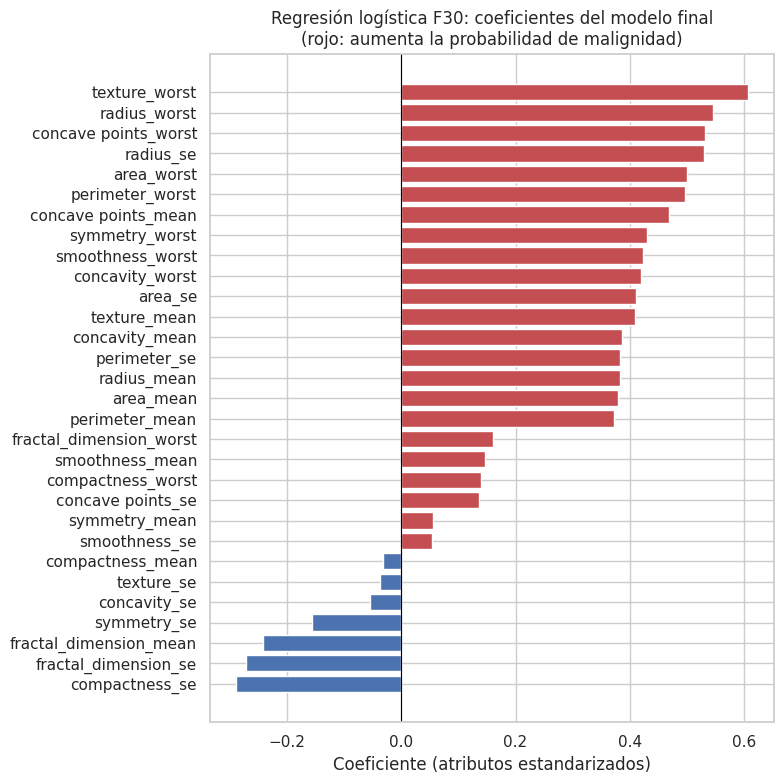

In [27]:
final_search = GridSearchCV(build_pipeline("F30", MODELS["Reg. logística"]["estimator"]),
                            MODELS["Reg. logística"]["grid"],
                            scoring=f2_scorer, cv=inner_cv, n_jobs=-1)
final_search.fit(X, y)
final_lr = final_search.best_estimator_.named_steps["clf"]
print("Hiperparámetros elegidos:",
      {k.replace("clf__", ""): v for k, v in final_search.best_params_.items()})
print(f"F2 en validación interna (5-fold): {final_search.best_score_:.4f}")

coefs = pd.Series(final_lr.coef_[0], index=FEATURES).sort_values()
print(f"Atributos con coeficiente nulo: {(coefs == 0).sum()} de {len(coefs)}")

fig, ax = plt.subplots(figsize=(8, 8))
colors = np.where(coefs > 0, "#C44E52", "#4C72B0")
ax.barh(coefs.index, coefs.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coeficiente (atributos estandarizados)")
ax.set_title("Regresión logística F30: coeficientes del modelo final\n"
             "(rojo: aumenta la probabilidad de malignidad)")
plt.tight_layout()
plt.show()

**Atributos de Street et al. en el modelo final.** Se verifica qué peso asigna la regresión logística a los tres atributos de F3 y cuál es su posición en el ranking por magnitud absoluta.

In [28]:
ranking = coefs.abs().rank(ascending=False).astype(int)
pd.DataFrame({"coeficiente": coefs[F3_FEATURES],
              "posición por |coef| (de 30)": ranking[F3_FEATURES]})

,coeficiente,posición por |coef| (de 30)
texture_mean,0.4086,12
area_worst,0.4993,5
smoothness_worst,0.4233,9


## 11. Discusión de resultados

> Los valores citados corresponden a nuestra ejecución con `SEED = 42`. Con otra semilla o versión de scikit-learn pueden variar ligeramente en los decimales.

### 11.1 Desempeño general

- **La regresión logística obtuvo el mayor recall en las tres representaciones** (0.961 en F30, 0.967 en F3 y 0.964 en PCA95). También obtuvo el mejor F2, accuracy (≈ 0.97) y AUC (≈ 0.99), con una precisión (≈ 0.96) equivalente a la de KNN. Es decir, el mayor recall **no se obtiene a costa de más falsos positivos**: en promedio deja sin detectar unos 8 de los 212 tumores malignos y genera unos 9 falsos positivos.
- **KNN** tiene la mayor especificidad (0.98 en F30), pero pierde más malignos (≈ 13 falsos negativos en F30). El lazo interno prefirió mayoritariamente la distancia Manhattan ($p = 1$) y $k = 3$.
- **El árbol de clasificación** es el modelo más débil e inestable: tiene la menor precisión y especificidad (≈ 22–25 falsos positivos) y eligió 14 a 18 combinaciones de hiperparámetros distintas en 30 folds, lo que confirma su sensibilidad a pequeñas variaciones de los datos.
- Las 9 configuraciones **superan con significancia al clasificador base** más exigente (“siempre maligno”, F2 = 0.748), así que todos los modelos aprenden un patrón útil.
- El AUC ≈ 0.99 de la regresión logística respalda el supuesto de **separabilidad casi lineal** de Wolberg y Mangasarian [3] y Street et al. [2].

### 11.2 Hipótesis H1

| Sub-hipótesis | Resultado | ¿Se cumple? |
|---|---|---|
| H1a: recall RL > 95 % | Media 0.961, pero IC 95 % corregido [0.930, 0.991]; prueba unilateral p = 0.24 | **Parcialmente:** se cumple en promedio, pero no es estadísticamente concluyente |
| H1b: RL significativamente mayor que el árbol | +4.1 puntos porcentuales; p (Holm) = 0.87 | **No** |
| H1c: RL al menos comparable a KNN | +2.4 puntos porcentuales; no significativamente menor | **Sí** |

La diferencia a favor de la regresión logística es **consistente en las tres representaciones**, pero la prueba de Nadeau-Bengio no la declara significativa salvo en un caso (RL vs KNN en F3, p (Holm) = 0.039). Esto se explica por la baja potencia del contraste: cada fold de prueba contiene solo ≈ 21 tumores malignos, de modo que **un único falso negativo mueve el recall del fold en ≈ 4.8 puntos**. Además, la corrección de varianza multiplica el error estándar por $\sqrt{0.145 \cdot J} \approx 2$ respecto a la prueba t ingenua. Este conservadurismo es justamente el que motivó usar la prueba corregida, y evita declarar diferencias espurias.

### 11.3 Hipótesis H2 y efecto de la representación (objetivo iii)

- Con F3, **la regresión logística alcanza una accuracy de 0.974**, coherente con el 97.0 % reportado por Street et al. [2] con los mismos tres atributos. KNN (0.951) y el árbol (0.936) quedan por debajo de ese valor.
- La segunda parte de H2 (F3 no supera el recall de F30) **solo se cumple para KNN**. En la regresión logística (+0.6 pp) y en el árbol (+0.9 pp) F3 es ligeramente mejor, aunque **ninguna diferencia entre representaciones es significativa** (p (Holm) = 1.0 en las 9 comparaciones de recall y accuracy).
- Conclusión: **tres atributos nucleares (`texture_mean`, `area_worst`, `smoothness_worst`) conservan prácticamente toda la información diagnóstica**. Una representación compacta y más interpretable no sacrifica desempeño. En el modelo final con 30 atributos, la regresión logística ubicó a `area_worst` entre los 5 atributos de mayor peso.

### 11.4 Respuesta a la pregunta de investigación

La **regresión logística** es el algoritmo con mayor recall en la clase maligna (≈ 0.96–0.97) y logra el mejor equilibrio con la precisión (≈ 0.96). Su ventaja sobre KNN y el árbol es consistente pero, con 569 muestras y el protocolo de 10×3 particiones, solo es estadísticamente significativa frente a KNN en la representación F3.

### 11.5 Limitaciones y trabajo futuro

- El umbral de decisión se fijó en $\hat p \geq 0.5$. Como sugieren Street et al. [2], desplazar el umbral (por ejemplo, elegirlo en el lazo interno) permitiría aumentar el recall a cambio de algunos falsos positivos adicionales, lo cual es aceptable clínicamente.
- El tamaño del dataset limita la potencia estadística. Más repeticiones no la aumentan sustancialmente, porque el término $n_{test}/n_{train}$ de la corrección no disminuye con $J$.
- WDBC proviene de un único centro clínico; los resultados deben validarse con datos externos (por ejemplo, de población peruana) antes de cualquier uso como apoyo diagnóstico.